In [1]:
!pip install ucimlrepo


In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

# Fetch Bank Marketing dataset from UCI
bank_marketing = fetch_ucirepo(id=222)

# Separate input features and target
X = bank_marketing.data.features
y = bank_marketing.data.targets

# Combine features and target into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset downloaded successfully!")
print("Dataset shape:", df.shape)

# Display first five rows
df.head()

Dataset downloaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [3]:
# Display dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

Number of rows: 45211
Number of columns: 17

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        

In [4]:
# Save the original dataset
df.to_csv("bank_marketing.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [5]:
# Check the distribution of target variable

print("Target variable distribution:")
print(df['y'].value_counts())

print("\nTarget variable percentage:")
print(df['y'].value_counts(normalize=True) * 100)

Target variable distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target variable percentage:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


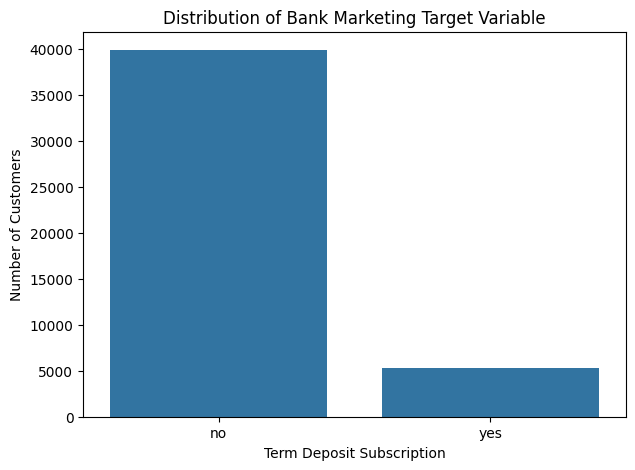

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title('Distribution of Bank Marketing Target Variable')
plt.xlabel('Term Deposit Subscription')
plt.ylabel('Number of Customers')

plt.show()

In [7]:
# Identify numerical columns
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical columns
categorical_columns = df.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

print("\nNumber of numerical columns:", len(numerical_columns))
print("Number of categorical columns:", len(categorical_columns))

Numerical columns:
['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

Number of numerical columns: 7
Number of categorical columns: 10


In [8]:
# Statistical summary of numerical columns

df[numerical_columns].describe()

,age,balance,day_of_week,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [9]:
# Display unique values in categorical columns

for column in categorical_columns:
    print("\nColumn:", column)
    print(df[column].value_counts(dropna=False))


Column: job
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
NaN               288
Name: count, dtype: int64

Column: marital
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

Column: education
education
secondary    23202
tertiary     13301
primary       6851
NaN           1857
Name: count, dtype: int64

Column: default
default
no     44396
yes      815
Name: count, dtype: int64

Column: housing
housing
yes    25130
no     20081
Name: count, dtype: int64

Column: loan
loan
no     37967
yes     7244
Name: count, dtype: int64

Column: contact
contact
cellular     29285
NaN          13020
telephone     2906
Name: count, dtype: int64

Column: month
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403

In [10]:
# Separate input features and target variable

X = df.drop(columns=['y', 'duration'])

y = df['y']

# Display the dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget values:")
print(y.unique())

Features shape: (45211, 15)
Target shape: (45211,)

Input features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Target values:
['no' 'yes']


In [11]:
# Identify numerical and categorical predictors

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTotal numerical features:", len(numerical_features))
print("Total categorical features:", len(categorical_features))
print("Total input features:", len(X.columns))

Numerical features:
['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Total numerical features: 6
Total categorical features: 9
Total input features: 15


In [12]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dataset sizes

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (36168, 15)
Testing features: (9043, 15)

Training target: (36168,)
Testing target: (9043,)

Training target distribution:
y
no     88.301814
yes    11.698186
Name: proportion, dtype: float64

Testing target distribution:
y
no     88.300343
yes    11.699657
Name: proportion, dtype: float64


In [13]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check target distribution

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (36168, 15)
Testing features: (9043, 15)

Training target: (36168,)
Testing target: (9043,)

Training target distribution:
y
no     31937
yes     4231
Name: count, dtype: int64

Testing target distribution:
y
no     7985
yes    1058
Name: count, dtype: int64


In [14]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [15]:
# Numerical feature preprocessing

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

print("Numerical preprocessing created successfully!")

Numerical preprocessing created successfully!


In [16]:
# Categorical feature preprocessing

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

print("Categorical preprocessing created successfully!")

Categorical preprocessing created successfully!


In [17]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Complete preprocessing pipeline created successfully!")

Complete preprocessing pipeline created successfully!


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.pipeline import Pipeline

print("All five ML algorithms imported successfully!")

All five ML algorithms imported successfully!


In [19]:
# Create Logistic Regression pipeline

logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Train the model

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [20]:
# Predict using test data

logistic_predictions = logistic_model.predict(X_test)

# Display first 10 predictions

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(logistic_predictions[:10])

First 10 actual values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

First 10 predicted values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [21]:
# Create Decision Tree pipeline

decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        max_depth=8
    ))
])

# Train the model

decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [22]:
# Predict using Decision Tree

decision_tree_predictions = decision_tree_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(decision_tree_predictions[:10])

First 10 actual values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

First 10 predicted values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [23]:
# Create KNN pipeline

knn_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(
        n_neighbors=5
    ))
])

# Train the model

knn_model.fit(X_train, y_train)

print("KNN trained successfully!")


KNN trained successfully!


In [24]:
# Predict using KNN

knn_predictions = knn_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(knn_predictions[:10])

First 10 actual values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

First 10 predicted values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [25]:
# Create Naive Bayes pipeline

naive_bayes_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GaussianNB())
])

# Train the model

naive_bayes_model.fit(X_train, y_train)

print("Naive Bayes trained successfully!")

Naive Bayes trained successfully!


In [26]:
# Predict using Naive Bayes

naive_bayes_predictions = naive_bayes_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(naive_bayes_predictions[:10])

First 10 actual values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

First 10 predicted values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [27]:
from sklearn.svm import LinearSVC

# Create SVM pipeline

svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

# Train SVM

svm_model.fit(X_train, y_train)

print("SVM trained successfully!")

SVM trained successfully!


In [28]:
svm_predictions = svm_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(svm_predictions[:10])

First 10 actual values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

First 10 predicted values:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


In [29]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

import pandas as pd

In [30]:
def evaluate_model(name, model, X_test, y_test):

    # Generate predictions
    y_pred = model.predict(X_test)

    # Get prediction scores for the positive class ('yes')
    classifier = model.named_steps['classifier']

    if hasattr(model, "predict_proba"):
        positive_index = list(classifier.classes_).index('yes')
        y_score = model.predict_proba(X_test)[:, positive_index]
    else:
        y_score = model.decision_function(X_test)

    # Calculate evaluation metrics
    results = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_score),
        'Precision': precision_score(y_test, y_pred, pos_label='yes', zero_division=0),
        'Recall': recall_score(y_test, y_pred, pos_label='yes', zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, pos_label='yes', zero_division=0),
        'MCC': matthews_corrcoef(y_test, y_pred)
    }

    return results

print("Evaluation function created successfully!")

Evaluation function created successfully!


In [31]:
models = {
    'Logistic Regression': logistic_model,
    'Decision Tree': decision_tree_model,
    'KNN': knn_model,
    'Naive Bayes': naive_bayes_model,
    'SVM': svm_model
}

results = []

for name, model in models.items():
    result = evaluate_model(name, model, X_test, y_test)
    results.append(result)

results_df = pd.DataFrame(results)

print("Evaluation Results:")
display(results_df.round(4))

Evaluation Results:


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8933,0.7717,0.6632,0.1786,0.2815,0.3065
1,Decision Tree,0.8933,0.7115,0.6303,0.2127,0.3180,0.3237
2,KNN,0.8874,0.7027,0.5529,0.1975,0.2911,0.2833
3,Naive Bayes,0.8452,0.7514,0.3708,0.4641,0.4123,0.3271
4,SVM,0.8932,0.7682,0.6513,0.1871,0.2907,0.3101


In [32]:
results_df.to_csv("model_evaluation_results.csv", index=False)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [33]:
import joblib
import os

# Create a folder to store the trained models
os.makedirs("model", exist_ok=True)

# Save all five trained models
joblib.dump(logistic_model, "model/logistic_regression.pkl")
joblib.dump(decision_tree_model, "model/decision_tree.pkl")
joblib.dump(knn_model, "model/knn.pkl")
joblib.dump(naive_bayes_model, "model/naive_bayes.pkl")
joblib.dump(svm_model, "model/svm.pkl")

print("All five models saved successfully!")

All five models saved successfully!


In [34]:
# Combine test features and actual target values
test_data = X_test.copy()
test_data['y'] = y_test.values

# Save the test dataset
test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Dataset shape:", test_data.shape)

display(test_data.head())

Test dataset saved successfully!
Dataset shape: (9043, 16)


,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,campaign,pdays,previous,poutcome,y
1392,40,blue-collar,married,primary,no,640,yes,yes,NaN,8,may,2,-1,0,NaN,no
7518,44,technician,married,secondary,no,378,yes,no,NaN,30,may,2,-1,0,NaN,no
12007,31,services,married,secondary,no,356,yes,no,NaN,20,jun,5,-1,0,NaN,no
5536,36,blue-collar,married,primary,no,655,yes,no,NaN,23,may,4,-1,0,NaN,no
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,1,-1,0,NaN,no


In [35]:
import os

print("Files saved in the model folder:")

for file in os.listdir("model"):
    print(file)

print("\nTest dataset exists:", os.path.exists("test_data.csv"))
print("Evaluation results exist:", os.path.exists("model_evaluation_results.csv"))

Files saved in the model folder:
knn.pkl
naive_bayes.pkl
svm.pkl
decision_tree.pkl
logistic_regression.pkl

Test dataset exists: True
Evaluation results exist: True


In [36]:
import sklearn
import pandas
import numpy
import joblib

print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)
print("joblib:", joblib.__version__)

scikit-learn: 1.6.1
pandas: 2.2.3
numpy: 2.4.6
joblib: 1.6.0


In [37]:
requirements = """streamlit
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0
matplotlib
seaborn
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print(requirements)

streamlit
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0
matplotlib
seaborn



In [38]:
from google.colab import files
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

st.set_page_config(
    page_title="Bank Marketing Prediction",
    page_icon="📊",
    layout="wide"
)

st.title("Bank Marketing Classification")
st.write(
    "Upload a test dataset and select a trained machine learning model "
    "to evaluate its performance."
)

# Load saved models
@st.cache_resource
def load_models():
    return {
        "Logistic Regression": joblib.load("model/logistic_regression.pkl"),
        "Decision Tree": joblib.load("model/decision_tree.pkl"),
        "KNN": joblib.load("model/knn.pkl"),
        "Naive Bayes": joblib.load("model/naive_bayes.pkl"),
        "SVM": joblib.load("model/svm.pkl")
    }

models = load_models()

# Expected input features
required_features = [
    "age", "job", "marital", "education", "default",
    "balance", "housing", "loan", "contact", "day_of_week",
    "month", "campaign", "pdays", "previous", "poutcome"
]

uploaded_file = st.file_uploader(
    "Upload your test CSV file",
    type=["csv"]
)

selected_model = st.selectbox(
    "Select a classification model",
    list(models.keys())
)

if uploaded_file is not None:

    data = pd.read_csv(uploaded_file)

    st.subheader("Uploaded Dataset")
    st.write("Dataset shape:", data.shape)
    st.dataframe(data.head())

    missing_features = [
        col for col in required_features if col not in data.columns
    ]

    if missing_features:
        st.error(f"Missing required columns: {missing_features}")

    elif "y" not in data.columns:
        st.error(
            "The uploaded CSV must contain the actual target column 'y' "
            "to calculate evaluation metrics."
        )

    else:
        X = data[required_features]
        y_true = data["y"]

        model = models[selected_model]

        y_pred = model.predict(X)

        classifier = model.named_steps["classifier"]

        if hasattr(model, "predict_proba"):
            positive_index = list(classifier.classes_).index("yes")
            y_score = model.predict_proba(X)[:, positive_index]
        else:
            y_score = model.decision_function(X)

        # Calculate metrics
        accuracy = accuracy_score(y_true, y_pred)
        auc = roc_auc_score(y_true, y_score)
        precision = precision_score(
            y_true, y_pred, pos_label="yes", zero_division=0
        )
        recall = recall_score(
            y_true, y_pred, pos_label="yes", zero_division=0
        )
        f1 = f1_score(
            y_true, y_pred, pos_label="yes", zero_division=0
        )
        mcc = matthews_corrcoef(y_true, y_pred)

        st.subheader("Model Evaluation Results")
        st.write("Selected model:", selected_model)

        col1, col2, col3 = st.columns(3)
        col1.metric("Accuracy", f"{accuracy:.4f}")
        col2.metric("AUC", f"{auc:.4f}")
        col3.metric("Precision", f"{precision:.4f}")

        col4, col5, col6 = st.columns(3)
        col4.metric("Recall", f"{recall:.4f}")
        col5.metric("F1 Score", f"{f1:.4f}")
        col6.metric("MCC", f"{mcc:.4f}")

        # Confusion matrix
        st.subheader("Confusion Matrix")

        cm = confusion_matrix(y_true, y_pred, labels=["no", "yes"])

        fig, ax = plt.subplots()
        display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["no", "yes"]
        )
        display.plot(ax=ax, cmap="Blues", values_format="d")
        st.pyplot(fig)
        plt.close(fig)

        # Classification report
        st.subheader("Classification Report")
        report = classification_report(
            y_true,
            y_pred,
            labels=["no", "yes"],
            zero_division=0,
            output_dict=True
        )
        st.dataframe(pd.DataFrame(report).transpose())

        # Predictions
        st.subheader("Predictions")
        output = data.copy()
        output["predicted_y"] = y_pred
        st.dataframe(output.head(20))

        csv = output.to_csv(index=False).encode("utf-8")

        st.download_button(
            label="Download predictions",
            data=csv,
            file_name="bank_marketing_predictions.csv",
            mime="text/csv"
        )
'''

with open("app.py", "w") as file:
    file.write(app_code)

print("app.py created successfully!")

app.py created successfully!


In [40]:
import py_compile
import joblib
import os

# Check Python syntax
py_compile.compile("app.py", doraise=True)
print("App syntax check: Passed")

# Check that all saved models can be loaded
model_files = [
    "logistic_regression.pkl",
    "decision_tree.pkl",
    "knn.pkl",
    "naive_bayes.pkl",
    "svm.pkl"
]

for file in model_files:
    model = joblib.load(os.path.join("model", file))
    print(file, "- Loaded successfully")

print("\nAll application checks completed!")

App syntax check: Passed
logistic_regression.pkl - Loaded successfully
decision_tree.pkl - Loaded successfully
knn.pkl - Loaded successfully
naive_bayes.pkl - Loaded successfully
svm.pkl - Loaded successfully

All application checks completed!


In [41]:
import os
import shutil

# Create main project folder
project_folder = "Bank_Marketing_ML_Project"
os.makedirs(project_folder, exist_ok=True)

# Create model folder inside project
os.makedirs(f"{project_folder}/model", exist_ok=True)

# Copy application and requirements
shutil.copy("app.py", project_folder)
shutil.copy("requirements.txt", project_folder)

# Copy test dataset and evaluation results
shutil.copy("test_data.csv", project_folder)
shutil.copy("model_evaluation_results.csv", project_folder)

# Copy all five trained models
for file in os.listdir("model"):
    shutil.copy(
        f"model/{file}",
        f"{project_folder}/model/{file}"
    )

print("Project folder created successfully!")

for root, dirs, files_list in os.walk(project_folder):
    print(root, files_list)

Project folder created successfully!
Bank_Marketing_ML_Project ['app.py', 'requirements.txt', 'test_data.csv', 'model_evaluation_results.csv']
Bank_Marketing_ML_Project/model ['knn.pkl', 'naive_bayes.pkl', 'svm.pkl', 'decision_tree.pkl', 'logistic_regression.pkl']


In [42]:
readme_content = """
# Bank Marketing Classification Project

## 1. Project Overview

This project implements and compares five machine learning classification
algorithms to predict whether a bank customer will subscribe to a term deposit.

The project also includes a Streamlit application that allows users to upload
a CSV dataset, select a trained model, and view its evaluation results.

## 2. Dataset

- Dataset: Bank Marketing
- Source: UCI Machine Learning Repository
- Dataset URL: https://archive.ics.uci.edu/dataset/222/bank+marketing
- Total records: 45,211
- Input features used: 15
- Target variable: y
- Target classes: yes and no

The duration feature was excluded because it represents call duration,
which is not known before contacting the customer.

## 3. Machine Learning Algorithms

The following five classification algorithms were implemented:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

## 4. Data Preprocessing

The preprocessing steps include:

- Handling missing numerical values using median imputation.
- Handling missing categorical values using constant imputation.
- Scaling numerical features using StandardScaler.
- Encoding categorical features using OneHotEncoder.
- Splitting the dataset into 80% training data and 20% testing data.
- Using stratified sampling to preserve class proportions.

Preprocessing and classification are combined into pipelines.
The pipelines are saved along with the trained models.

## 5. Evaluation Metrics

Each model is evaluated using:

- Accuracy
- Area Under the ROC Curve (AUC)
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

The dataset has an imbalanced target distribution, so multiple
evaluation metrics are considered instead of relying only on accuracy.

## 6. Project Structure

Bank_Marketing_ML_Project/
|
|-- app.py
|-- requirements.txt
|-- README.md
|-- test_data.csv
|-- model_evaluation_results.csv
|
|-- model/
    |-- logistic_regression.pkl
    |-- decision_tree.pkl
    |-- knn.pkl
    |-- naive_bayes.pkl
    |-- svm.pkl

## 7. Streamlit Application

The application provides the following features:

- CSV file upload.
- Selection of one of the five trained models.
- Calculation of six evaluation metrics.
- Confusion matrix visualization.
- Classification report.
- Prediction results with CSV download.

The application loads saved models and does not retrain them.

## 8. Installation and Execution

Install the required packages:

pip install -r requirements.txt

Run the Streamlit application:

streamlit run app.py

## 9. Files Included

- app.py: Streamlit application.
- requirements.txt: Required Python packages.
- test_data.csv: Test dataset with actual target values.
- model_evaluation_results.csv: Model comparison results.
- model/: Saved trained machine learning pipelines.

## 10. Author

Machine Learning Assignment 2
BITS Pilani - Work Integrated Learning Programme
"""

readme_path = "Bank_Marketing_ML_Project/README.md"

with open(readme_path, "w") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [43]:
with open("Bank_Marketing_ML_Project/README.md", "r") as file:
    print(file.read())


# Bank Marketing Classification Project

## 1. Project Overview

This project implements and compares five machine learning classification
algorithms to predict whether a bank customer will subscribe to a term deposit.

The project also includes a Streamlit application that allows users to upload
a CSV dataset, select a trained model, and view its evaluation results.

## 2. Dataset

- Dataset: Bank Marketing
- Source: UCI Machine Learning Repository
- Dataset URL: https://archive.ics.uci.edu/dataset/222/bank+marketing
- Total records: 45,211
- Input features used: 15
- Target variable: y
- Target classes: yes and no

The duration feature was excluded because it represents call duration,
which is not known before contacting the customer.

## 3. Machine Learning Algorithms

The following five classification algorithms were implemented:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

## 4. Data Preprocessing



In [44]:
import shutil
from google.colab import files

shutil.make_archive(
    "Bank_Marketing_ML_Project",
    "zip",
    root_dir="Bank_Marketing_ML_Project"
)

print("Project ZIP created successfully!")

files.download("Bank_Marketing_ML_Project.zip")

Project ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>